# MAGI v1.0.0: the IAPS Triple model, five sources

This notebook loads the five trained models shipped in `trained_models/` (K-40, Ra-226, Th-232, gamma and cosmic muons), generates the crossings of each source on the tracking ball, and checks and plots them. It replaces the single experiment notebook of v0.8.2 and needs no training data.

**What the models are.** Each model is a `CVAE_MixEnergy_ContPhi_TaskAdaptive` (the v0.8 mixture head with a continuum flow and pinned line components) trained with the v1.0.0 recipe on the first entries of the MultiVerse ball of the IAPS Triple mass model (centre (0, 0, 5) mm, R = 105 mm). A *crossing* is the first inward entry of a track into the ball, so a model gives the particles that enter the ball, and Geant4 transports them inside. The five artifact sets are in `trained_models/IAPS_<source>/` and must stay together (weights, config, metadata, task weights, quantile transformers, prior-refit history).

**What is not here.** The training data (about 12 million crossings per source) is not versioned. The comparison with the real crossings, the per-bin RMS and the detector-level closure are in `docs/manual/magi_manual.pdf` (Accuracy) and in `CHANGELOG.md`: the 5x re-injection closure gives R = 0.97 ± 0.02 pooled, with Th (0.88) and Ra (0.86) declared as low.

**Run it.** From the repository root, in an environment with the packages of `requirements.txt` (`pip install -r requirements.txt`, or `pip install -e MAGI_package/`). On CPU the generation takes seconds to a few minutes per source.

## 1 · Setup

In [1]:
import os, sys, json, time, subprocess, tempfile
import numpy as np
import matplotlib.pyplot as plt

ROOT = os.getcwd()
while not os.path.isdir(os.path.join(ROOT, "trained_models")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.insert(0, os.path.join(ROOT, "MAGI_package"))   # lets the notebook run from a clone without pip install

SOURCES = {"K40": "$^{40}$K", "Ra226": "$^{226}$Ra", "Th232": "$^{232}$Th", "gamma": r"$\gamma$ (cosmic)", "mu": r"$\mu$ (cosmic)"}
N_GEN = 100_000
OUT = tempfile.mkdtemp(prefix="magi_iaps_")
print("repository:", ROOT, "| output:", OUT)
for s in SOURCES:
    d = f"trained_models/IAPS_{s}"
    print(f"{s:6s}", "ok" if os.path.exists(f"{d}/mix_{s}.weights.h5") and os.path.exists(f"{d}/mix_{s}_quantile_transformers.joblib") else "MISSING", sorted(os.listdir(d))[:3], "...")

repository: /Volumes/T7/MAGI-public | output: /var/folders/l7/67sx0h9j2zz3l3b80sx34dj00000gn/T/magi_iaps_k_xdo177
K40    ok ['mix_K40.weights.h5', 'mix_K40_config.json', 'mix_K40_history.json'] ...
Ra226  ok ['mix_Ra226.weights.h5', 'mix_Ra226_config.json', 'mix_Ra226_history.json'] ...
Th232  ok ['mix_Th232.weights.h5', 'mix_Th232_config.json', 'mix_Th232_history.json'] ...
gamma  ok ['mix_gamma.weights.h5', 'mix_gamma_config.json', 'mix_gamma_history.json'] ...
mu     ok ['mix_mu.weights.h5', 'mix_mu_config.json', 'mix_mu_history.json'] ...


## 2 · What a model contains

The metadata file holds everything generation needs: the geometry transform, the sphere, the energy bins, the pinned lines and the type probabilities. The string `geometry_transform` is a contract between training and generation and is read from here, never typed again by hand.

In [2]:
meta = {}
for s in SOURCES:
    m = json.load(open(f"trained_models/IAPS_{s}/mix_{s}_metadata.json"))
    meta[s] = m
    p = m["preprocessing_metadata"]; p = eval(p) if isinstance(p, str) else p
    print(f"{s:6s} class={m['model_class']}  transform={p['geometry_transform']}  ball: centre={p['center']} R={p['radius']:.1f} mm  "
          f"types={p['idx_to_type']}  lines={len(p.get('matched_lines', []))}")

K40    class=CVAE_MixEnergy_ContPhi_TaskAdaptive  transform=quantile_u_r_u_v_phi_r_phi_v  ball: centre=[0.0, 0.0, 5.0] R=105.0 mm  types={'0': 'gamma', '1': 'e-'}  lines=6
Ra226  class=CVAE_MixEnergy_ContPhi_TaskAdaptive  transform=quantile_u_r_u_v_phi_r_phi_v  ball: centre=[0.0, 0.0, 5.0] R=105.0 mm  types={'0': 'gamma', '1': 'e-'}  lines=32
Th232  class=CVAE_MixEnergy_ContPhi_TaskAdaptive  transform=quantile_u_r_u_v_phi_r_phi_v  ball: centre=[0.0, 0.0, 5.0] R=105.0 mm  types={'0': 'gamma', '1': 'e-', '2': 'e+'}  lines=32
gamma  class=CVAE_MixEnergy_ContPhi_TaskAdaptive  transform=quantile_u_r_u_v_phi_r_phi_v  ball: centre=[0.0, 0.0, 5.0] R=105.0 mm  types={'0': 'gamma', '1': 'e-', '2': 'e+'}  lines=6
mu     class=CVAE_MixEnergy_ContPhi_TaskAdaptive  transform=quantile_u_r_u_v_phi_r_phi_v  ball: centre=[0.0, 0.0, 5.0] R=105.0 mm  types={'0': 'mu-', '1': 'gamma', '2': 'e-', '3': 'e+'}  lines=6


## 3 · Generation

`scripts/generate_geant_source.py` reloads a run from its metadata and transformers, samples the latent prior, decodes, and reconstructs the physical quantities `E, x, y, z, vx, vy, vz` on the sphere. The text format has one crossing per row: particle name, energy (MeV), position (mm), direction cosines. The `binary` format writes the file that the Geant4 re-injection reads (Section 6).

In [3]:
def generate(s, n=N_GEN, seed=7, fmt="text"):
    d = f"trained_models/IAPS_{s}"
    out = f"{OUT}/gen_{s}.{'txt' if fmt == 'text' else 'gntbin'}"
    t0 = time.time()
    r = subprocess.run([sys.executable, "scripts/generate_geant_source.py", "--save-dir", d, "--model-name", f"mix_{s}",
                        "--metadata-file", f"{d}/mix_{s}_metadata.json", "--transformers-file", f"{d}/mix_{s}_quantile_transformers.joblib",
                        "--output-file", out, "--n-events", str(n), "--seed", str(seed), "--format", fmt],
                       capture_output=True, text=True, env={**os.environ, "PYTHONPATH": os.path.join(ROOT, "MAGI_package")})
    if r.returncode:
        raise RuntimeError(r.stderr[-2000:])
    print(f"{s:6s} {n:,} crossings in {time.time() - t0:5.0f} s")
    return out

files = {s: generate(s) for s in SOURCES}

K40    100,000 crossings in    49 s


Ra226  100,000 crossings in    40 s


Th232  100,000 crossings in    36 s


gamma  100,000 crossings in    32 s


mu     100,000 crossings in    32 s


In [4]:
COLS = ["name", "E", "x", "y", "z", "vx", "vy", "vz"]
def load(path):
    import pandas as pd
    return pd.read_csv(path, sep=r"\s+", header=None, names=COLS)

gen = {s: load(f) for s, f in files.items()}
for s, g in gen.items():
    print(f"\n{s}: {len(g):,} crossings, E from {g.E.min():.2e} to {g.E.max():.2e} MeV")
    print((g.name.value_counts(normalize=True).head(4) * 100).round(2).to_string())


K40: 100,000 crossings, E from 7.98e-03 to 1.46e+00 MeV
name
gamma    99.64
e-        0.36

Ra226: 100,000 crossings, E from 7.72e-03 to 3.34e+00 MeV
name
gamma    99.75
e-        0.25

Th232: 100,000 crossings, E from 4.18e-03 to 4.09e+00 MeV
name
gamma    99.71
e-        0.29
e+        0.00

gamma: 100,000 crossings, E from 2.22e-04 to 5.46e+02 MeV
name
gamma    96.78
e-        2.96
e+        0.26

mu: 100,000 crossings, E from 1.97e-04 to 2.43e+05 MeV
name
mu-      49.63
gamma    36.82
e-       13.50
e+        0.05


## 4 · Sanity checks

Two exact properties of every crossing: the position lies on the ball (distance to the centre equal to R) and the direction is a unit vector. Neither is imposed by hand on the output; the geometry transform of the model returns points on the sphere by construction, so a deviation signals a mismatch between the model and its metadata.

In [5]:
for s, g in gen.items():
    p = meta[s]["preprocessing_metadata"]; p = eval(p) if isinstance(p, str) else p
    c = np.array(p["center"]); R = p["radius"]
    r = np.linalg.norm(g[["x", "y", "z"]].values - c, axis=1)
    v = np.linalg.norm(g[["vx", "vy", "vz"]].values, axis=1)
    inward = ((g[["x", "y", "z"]].values - c) * g[["vx", "vy", "vz"]].values).sum(1) / (r * v) < 0
    print(f"{s:6s} |r-R| max {np.abs(r - R).max():.2e} mm | |v|-1 max {np.abs(v - 1).max():.1e} | inward {100 * inward.mean():.1f} %")

K40    |r-R| max 4.99e-07 mm | |v|-1 max 8.2e-10 | inward 98.9 %
Ra226  |r-R| max 5.00e-07 mm | |v|-1 max 8.2e-10 | inward 94.8 %
Th232  |r-R| max 5.00e-07 mm | |v|-1 max 8.1e-10 | inward 94.9 %
gamma  |r-R| max 5.01e-07 mm | |v|-1 max 8.4e-10 | inward 99.0 %
mu     |r-R| max 4.99e-07 mm | |v|-1 max 8.3e-10 | inward 99.1 %


## 5 · Spectra and angular distribution

Energy of the crossing particles for the five sources. The lines of the radioactive sources (for example the 1460.8 keV line of K-40, the 2614.5 keV line of Th-232 and the 609.3 keV line of Ra-226 daughters) are pinned components of the mixture head and appear as narrow spikes on the continuum. The cosine of the incidence angle is taken against the inward normal; 1 is normal incidence.

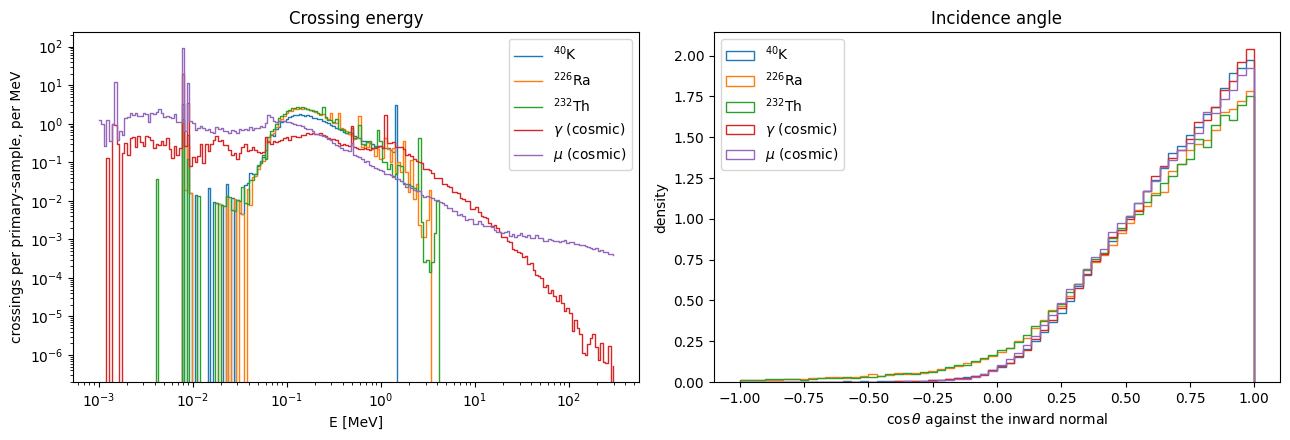

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(-3, 2.5, 200)
for s, g in gen.items():
    h, _ = np.histogram(g.E, bins=bins)
    ax[0].step(bins[:-1], h / len(g) / np.diff(bins), where="post", label=SOURCES[s], lw=1)
ax[0].set(xscale="log", yscale="log", xlabel="E [MeV]", ylabel="crossings per primary-sample, per MeV", title="Crossing energy")
ax[0].legend()
for s, g in gen.items():
    p = meta[s]["preprocessing_metadata"]; p = eval(p) if isinstance(p, str) else p
    c = np.array(p["center"]); n = -(g[["x", "y", "z"]].values - c); n /= np.linalg.norm(n, axis=1)[:, None]
    mu = (n * g[["vx", "vy", "vz"]].values).sum(1)
    ax[1].hist(mu, bins=60, range=(-1, 1), histtype="step", density=True, label=SOURCES[s])
ax[1].set(xlabel=r"$\cos\theta$ against the inward normal", ylabel="density", title="Incidence angle"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6 · From crossings to a Geant4 run

The generated crossings are particles on the ball, so the downstream run is a Geant4 job that injects them at that ball and transports them in the mass model. The injector, the tracking ball and the first-entry rule are in `Geant4_src/` (read `Geant4_src/README.md` first). The call below writes a binary file for the muon model. In the Geant4 macro, `/generator/generatedFormat binary` and `/generator/generatedFile <path>` read it, with `/MultiVerse/radius` and `/MultiVerse/centre` set to the values printed in Section 2.

In [7]:
gntbin = generate("mu", n=10_000, seed=11, fmt="binary")
print(gntbin, os.path.getsize(gntbin), "bytes")

mu     10,000 crossings in    28 s
/var/folders/l7/67sx0h9j2zz3l3b80sx34dj00000gn/T/magi_iaps_k_xdo177/gen_mu.gntbin 320020 bytes


## 7 · Where to go next

- `docs/manual/magi_manual.pdf`: theory, every function and setting, the validation record and the limits of v1.0.0.
- `Example_Usage.ipynb`: the full pipeline (load, preprocess, train, generate, validate) on synthetic data, to adapt to a new source.
- `tools/train_iaps.py`: the training recipe of the five models shown here.
- `Geant4_src/`: the tracking ball, the first-entry rule and the injector.